# 天衍8比特预检结果复核

本Notebook使用2026年11月14日真实天衍返回结果的公开汇总。12条线路，每条128 shots；原始读数在私有证据中保存。此处不登录或提交云任务，不使用股票数据，不提供股票准确率。

学习目标：区分原始读数核验、冻结统计检查、梯度精度与完整搜索有效性。

In [1]:
from pathlib import Path
import csv, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reports/qukernet_cloud_v2/preflight8_20261114.csv").is_file())
folder = root / "reports/qukernet_cloud_v2"
with (folder / "preflight8_20261114.csv").open(encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
summary = json.loads((folder / "preflight8_20261114.json").read_text(encoding="utf-8"))
assert len(rows) == 12 and sum(int(r["shots"]) for r in rows) == 1536
assert all(int(r["accept_low"]) <= int(r["zero_count"]) <= int(r["accept_high"]) for r in rows)
[(r["name"], int(r["zero_count"]), int(r["shots"])) for r in rows]

[('kernel8-same-x-v1', 128, 128),
 ('kernel8-same-z-v1', 128, 128),
 ('kernel8-pair-xz-v1', 92, 128),
 ('kernel8-pair-zx-v1', 106, 128),
 ('kernel8-param0-left-shift-1-v1', 44, 128),
 ('kernel8-param0-left-shift+1-v1', 46, 128),
 ('kernel8-param0-right-shift-1-v1', 49, 128),
 ('kernel8-param0-right-shift+1-v1', 34, 128),
 ('kernel8-param1-left-shift-1-v1', 47, 128),
 ('kernel8-param1-left-shift+1-v1', 55, 128),
 ('kernel8-param1-right-shift-1-v1', 42, 128),
 ('kernel8-param1-right-shift+1-v1', 47, 128)]

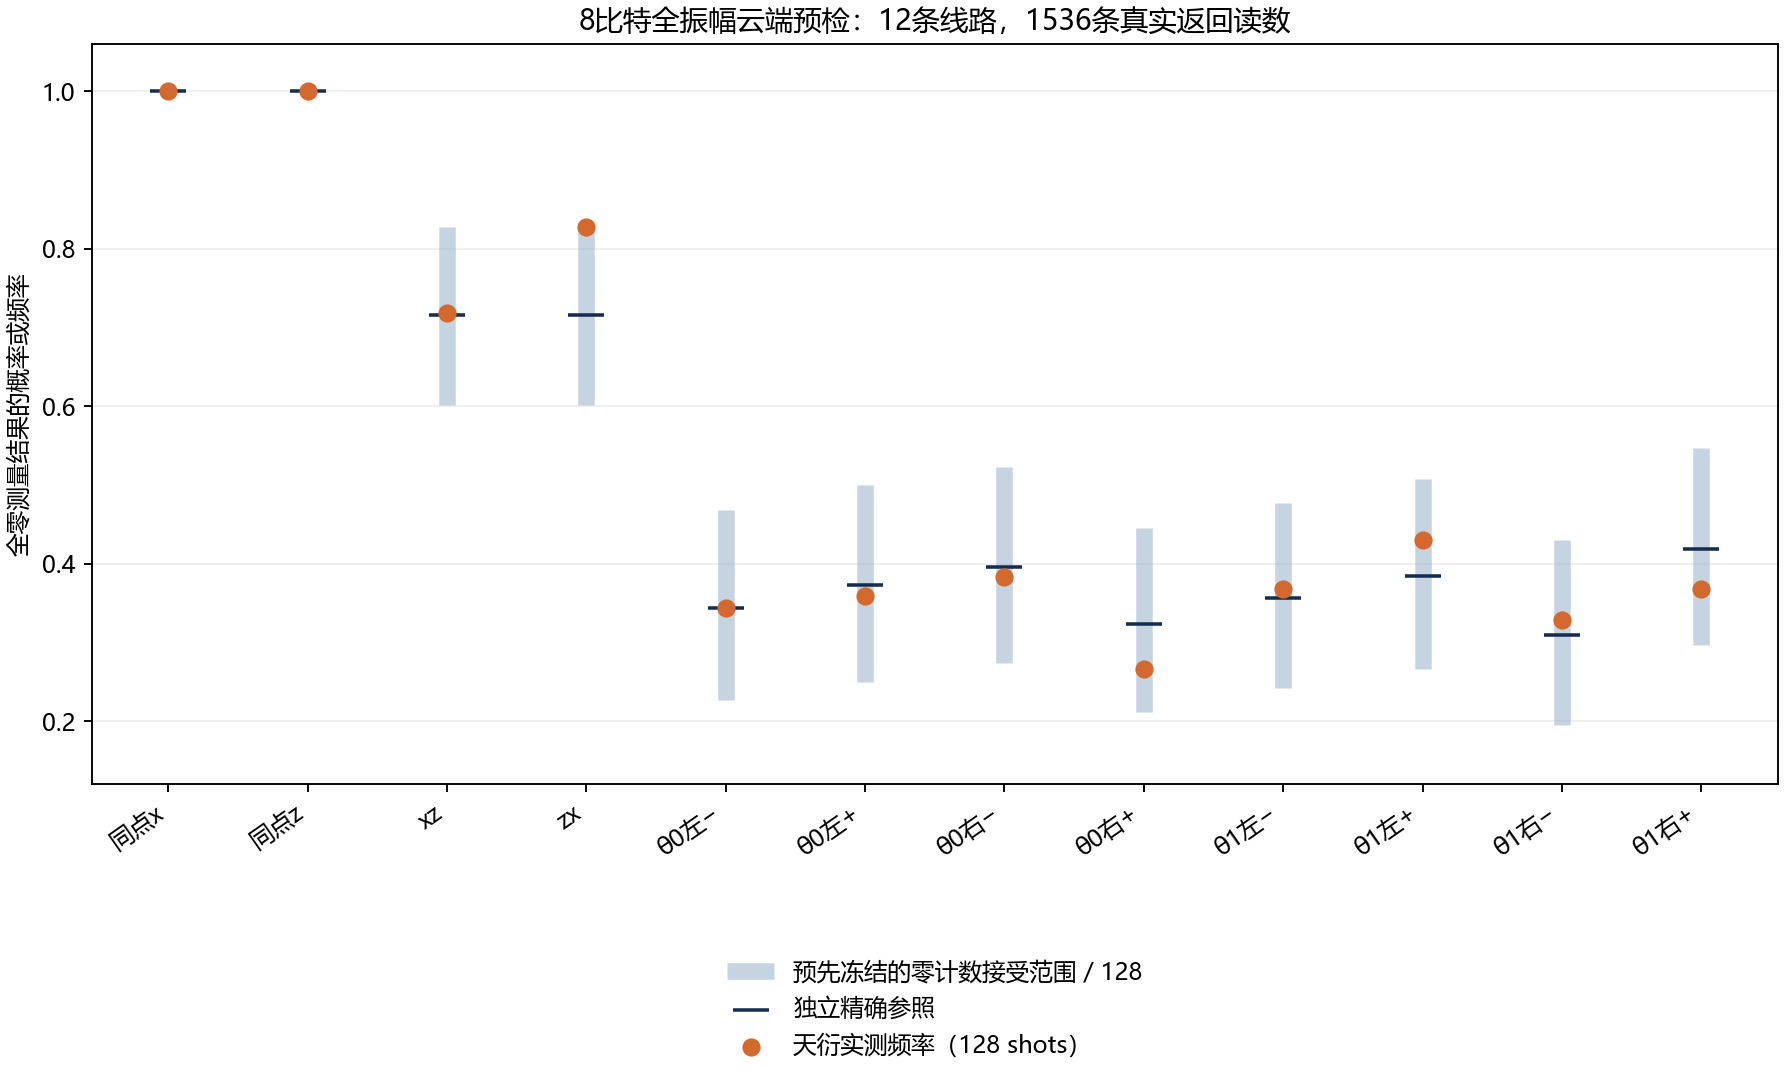

In [2]:
from IPython.display import Image, display
display(Image(filename=str(folder / "figures/preflight8_probability_20261114.png")))

In [3]:
p = {r["name"]: float(r["empirical_p0"]) for r in rows}
estimated = []
for k in range(2):
    prefix = f"kernel8-param{k}-"
    gradient = 0.5 * (p[prefix+"left-shift+1-v1"] - p[prefix+"left-shift-1-v1"]
                      - p[prefix+"right-shift+1-v1"] + p[prefix+"right-shift-1-v1"])
    estimated.append(gradient)
    print(k, "经验导数", gradient, "精确参照", summary["gradients"][k]["reference_derivative"])
assert abs(estimated[0] - 17/256) < 1e-12
assert abs(estimated[1] - 3/256) < 1e-12

0 经验导数 0.06640625 精确参照 0.05084990278613846
1 经验导数 0.01171875 精确参照 -0.04134160971511475


## 思考与验收

1. 为什么12个检查都通过，第二个梯度仍可能符号错误？
2. 为什么19.6秒客户端耗时不能当作模拟器纯计算耗时？
3. 交换输入的两个核估计不同，是否直接说明理论核不对称？

验收：复算1536条读数总量与两项经验导数，解释抽样误差；不把此预检称为完整QuKerNet搜索、股票预测改善或量子优势。冻结范围不是从本次读数估计的置信区间。